# Natural Language Processing 1 - Text as Data, Rules (TextBlob), TF-IDF and Logistic Regression

## Summary

In this notebook we try the ideas from the *Natural Language Processing 1 - Text as Data, Rules (TextBlob), TF-IDF and Logistic Regression* slides on real text, and we build **two sentiment analysers**: one from hand-written rules, and one that **learns** from the data.

**The task:** a **classification** problem. Read a review and predict one of 2 classes: **positive** or **negative**.

**The data:** 2,000 movie reviews from the NLTK library. Each review is labelled **positive** or **negative** by a person. We use the same reviews in all three NLP lessons, so at the end we can compare four different ways to detect sentiment.

**Outline:**

| Section | What we do | Why |
|---|---|---|
| 0–1 | Set up, load the reviews, Zipf's law | A few words are everywhere, most are rare |
| 2 | Tokenization (+ optional BPE) | Split text into words, the first step of every NLP task |
| 3 | Cleaning | Lowercase, remove stopwords, lemmatize, so that the same word always looks the same |
| 4 | POS tags and noun phrases | Find the adjectives (where opinions live) and the things people talk about |
| 5 | Which words take sides? | Do positive and negative reviews use different words? |
| 6 | Rule-based sentiment | Score every review with TextBlob: **row 1 of our scoreboard** |
| 7 | Bag of words | Turn every review into numbers |
| 8 | N-grams | Keep a little word order: "not funny". Why we stop at bigrams |
| 9 | TF-IDF | Give words that are everywhere less weight |
| 10 | Our first algorithm: logistic regression | Train on 1,600 reviews, test on 400, read the learned word weights: **row 2 of our scoreboard** |
| 11 | *(Optional)* Marvin the chatbot | A bot that answers based on your mood |
| 12 | *(Optional)* A text generator | Write new sentences with n-gram statistics |
| 13 | Recap | |

## 0. Setup

We load our libraries. Our data (**movie_reviews.csv**) and the NLTK tools we need (tokenizer, stopwords, dictionary, tagger, in the **nltk_data** folder)

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.data.path.insert(0, "nltk_data")

needed = {"tokenizers/punkt": "punkt", "tokenizers/punkt_tab": "punkt_tab", "corpora/stopwords": "stopwords",
          "corpora/wordnet": "wordnet", "corpora/omw-1.4": "omw-1.4", "corpora/brown": "brown",
          "taggers/averaged_perceptron_tagger": "averaged_perceptron_tagger",
          "taggers/averaged_perceptron_tagger_eng": "averaged_perceptron_tagger_eng"}
for resource, package in needed.items():
    try:
        nltk.data.find(resource + ".zip")
    except LookupError:
        print("Not in nltk_data, downloading:", package)
        nltk.download(package, quiet=True)
from textblob import TextBlob

pd.set_option("display.max_colwidth", 120)

## 1. Load the reviews

The reviews are in the file **movie_reviews.csv**, in the same folder as this notebook. It holds the 2,000 reviews of the NLTK `movie_reviews` collection, one row per review, with three columns: the original file name, the label (`pos` or `neg`) and the text.

In [2]:
df = pd.read_csv("movie_reviews.csv")
print("Reviews:", len(df))
df.sample(5, random_state=0)

Reviews: 2000


,fileid,label,text
405,neg/cv405_21868.txt,neg,"arnold schwarzenegger has been an icon for action enthusiasts , since the late 80's , but lately his films have been..."
1190,pos/cv190_27052.txt,pos,"good films are hard to find these days . \ngreat films are beyond rare . \nproof of life , russell crowe's one-two p..."
1132,pos/cv132_5618.txt,pos,quaid stars as a man who has taken up the proffesion of dragonslayer after he feels he is betrayed by a dragon early...
731,neg/cv731_3968.txt,neg,"we could paraphrase michelle pfieffer's character in dangerous minds and say that beyond rangoon starts with an "" a ..."
1754,pos/cv754_7216.txt,pos,kolya is one of the richest films i've seen in some time . \nzdenek sverak plays a confirmed old bachelor ( who's li...


In [3]:
df["label"].value_counts()

label
neg    1000
pos    1000
Name: count, dtype: int64

<span style="color:red;"><b>Question:</b> Why do we check how many reviews there are of each label?</span>

<span style="color:green;"><b>Answer:</b></span><br>
To know what a **good score** looks like. We have exactly 1,000 positive and 1,000 negative reviews, so the classes are **balanced**.

- A "model" that always says *positive* is already right **50%** of the time. Any real method has to beat 50%.
- If 90% of the reviews were positive, always saying *positive* would get 90% accuracy, without reading a single word. A high accuracy would then mean very little.

Let's read one review. Notice that the text is already lowercase and has spaces around the punctuation: someone cleaned it a little before us.

In [4]:
review = df.loc[df["fileid"] == "pos/cv754_7216.txt", "text"].iloc[0]
print(review)

kolya is one of the richest films i've seen in some time . 
zdenek sverak plays a confirmed old bachelor ( who's likely to remain so ) , who finds his life as a czech cellist increasingly impacted by the five-year old boy that he's taking care of . 
though it ends rather abruptly-- and i'm whining , 'cause i wanted to spend more time with these characters-- the acting , writing , and production values are as high as , if not higher than , comparable american dramas . 
this father-and-son delight-- sverak also wrote the script , while his son , jan , directed-- won a golden globe for best foreign language film and , a couple days after i saw it , walked away an oscar . 
in czech and russian , with english subtitles . 



In [5]:
df["n_words"] = df["text"].str.split().str.len()
df.groupby("label")["n_words"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
neg,1000.0,706.0,297.0,17.0,510.0,668.0,848.0,2181.0
pos,1000.0,787.0,353.0,130.0,544.0,732.0,957.0,2678.0


**What we see:**

- **Balanced classes:** 1,000 negative and 1,000 positive reviews. Always saying "positive" gives 50%, the score every method has to beat.
- **Long reviews:** a typical review has about 700 words (median: 668 negative, 732 positive), from 17 up to 2,678 words. A long review can praise *and* criticise, which makes sentiment harder.
- **Positive reviews are longer:** about 80 words more on average (787 vs 706), and the 25%, 50% and 75% values are higher too. Remember this for section 10: the model will notice it.
- **Mean > median:** a few very long reviews pull the average up. For skewed data like this, the median describes a typical review better.

### The words of NLP, and Zipf's law

- **Corpus:** all our texts (2,000 reviews). **Document:** one text (one review).
- **Token:** one piece of text, counted every time it appears. **Vocabulary:** the *different* tokens.

Let's count them, with a simple rule for now (keep only words, lowercase). The next section looks at tokenization properly.

Tokens: 1,303,661 | Vocabulary: 41,644 different words


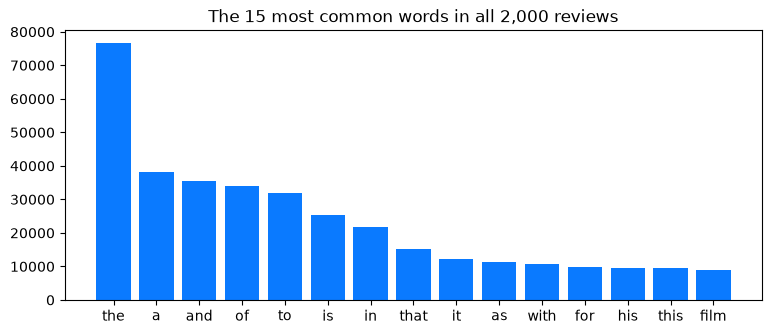

Top 10 words: 23% of all words
Top 100 words: 47% of all words
Words that appear only once: 36% of the vocabulary


In [6]:
all_tokens = Counter()
for text in df["text"]:
    all_tokens.update(re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower()))

n_tokens, n_types = sum(all_tokens.values()), len(all_tokens)
print(f"Tokens: {n_tokens:,} | Vocabulary: {n_types:,} different words")

top15 = all_tokens.most_common(15)
plt.figure(figsize=(9, 3.5))
plt.bar([w for w, _ in top15], [c for _, c in top15], color="#0A7AFF")
plt.title("The 15 most common words in all 2,000 reviews")
plt.show()

print(f"Top 10 words: {sum(c for _, c in all_tokens.most_common(10)) / n_tokens:.0%} of all words")
print(f"Top 100 words: {sum(c for _, c in all_tokens.most_common(100)) / n_tokens:.0%} of all words")
print(f"Words that appear only once: {sum(1 for c in all_tokens.values() if c == 1) / n_types:.0%} of the vocabulary")

**Zipf's law:** the 2nd most common word appears about half as often as the 1st (*the* 76,573 vs *a* 38,101), the 3rd about a third as often, and so on. A few words are everywhere (the top 10 make up almost a quarter of the text) and most words are rare (more than a third appear only once).

Both ends cause problems we solve in this notebook: very common words carry little meaning (stopwords in section 3, TF-IDF in section 9), very rare words are hard to learn (subword tokens in section 2).

## 2. Tokenization: splitting text into words

A computer sees text as one long string of characters. **Tokenization** splits it into pieces called **tokens**, usually words and punctuation. It sounds easy, so let's try three ways on a sentence from one of our negative reviews (`neg/cv499_11407.txt`). In the dataset the text is already lowercase and split, so here it is written the way the reviewer typed it:

In [7]:
from nltk.tokenize import word_tokenize, sent_tokenize

sentence = "I paid $4.25 for a matinee screening and don't have any way to get my money back, either."
satz = "Ich habe 4,25 $ für eine Matinee-Vorstellung bezahlt und bekomme mein Geld auch nicht zurück."   # the same in German

for name, text, language in [("English", sentence, "english"), ("German", satz, "german")]:
    print(f"--- {name} ---")
    print("1. split():      ", text.split())
    print("2. word_tokenize:", word_tokenize(text, language=language))
    print("3. regex:        ", re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower()))
    print()

--- English ---
1. split():       ['I', 'paid', '$4.25', 'for', 'a', 'matinee', 'screening', 'and', "don't", 'have', 'any', 'way', 'to', 'get', 'my', 'money', 'back,', 'either.']
2. word_tokenize: ['I', 'paid', '$', '4.25', 'for', 'a', 'matinee', 'screening', 'and', 'do', "n't", 'have', 'any', 'way', 'to', 'get', 'my', 'money', 'back', ',', 'either', '.']
3. regex:         ['i', 'paid', 'for', 'a', 'matinee', 'screening', 'and', "don't", 'have', 'any', 'way', 'to', 'get', 'my', 'money', 'back', 'either']

--- German ---
1. split():       ['Ich', 'habe', '4,25', '$', 'für', 'eine', 'Matinee-Vorstellung', 'bezahlt', 'und', 'bekomme', 'mein', 'Geld', 'auch', 'nicht', 'zurück.']
2. word_tokenize: ['Ich', 'habe', '4,25', '$', 'für', 'eine', 'Matinee-Vorstellung', 'bezahlt', 'und', 'bekomme', 'mein', 'Geld', 'auch', 'nicht', 'zurück', '.']
3. regex:         ['ich', 'habe', 'f', 'r', 'eine', 'matinee', 'vorstellung', 'bezahlt', 'und', 'bekomme', 'mein', 'geld', 'auch', 'nicht', 'zur', 'ck']



**First in English**

- **split()** only cuts at spaces, so punctuation sticks to the words: `back,` and `either.` are not the same tokens as `back` and `either`.
- **word_tokenize** knows the rules of English: it splits `don't` into `do` + `n't`, splits `$` from `4.25`, and separates the punctuation.
- **The regex** keeps only words made of letters (with an apostrophe inside, like `don't`). It is fast and simple, but the price `$4.25` disappears.

**What we see in German:**

- **split()** has the same problem as in English: *zurück.* keeps the full stop.
- **word_tokenize** works well with `language="german"`. It keeps *4,25* (German decimal comma) and *Matinee-Vorstellung* together.
- **Our regex breaks German words:** `[a-z]` only knows the 26 English letters, so *für* becomes *f* + *r*, and *zurück* becomes *zur* + *ck*. A tokenizer built for one language can fail silently on another.

`neg/cv499_11407.txt` is the review's **file ID**: the `fileid` column of `movie_reviews.csv`. Here is the sentence in the dataset, lowercase and with spaces around the punctuation:

In [8]:
review_499 = df.loc[df["fileid"] == "neg/cv499_11407.txt", "text"].iloc[0]
start = review_499.find("i paid")
print(review_499[start - 200 : start + 150])

d , too , " get me out of this theater ! " 
new line cinema spent millions of dollars creating the expressionistic film noir visuals and paying the actors , and doesn't have any way to get it back . 
i paid $4 . 25 for a matinee screening and don't have any way to get my money back , either . 
you'll hear a lot from other critics about the look and


<span style="color:red;"><b>Question:</b> Which tokenizer is the best?</span>

<span style="color:green;"><b>Answer:</b></span><br>
There is no single best one: it depends on the task.

- For **sentiment**, the regex is often good enough: the price doesn't tell us the opinion ("don't have any way to get my money back" does), and it is fast on 2,000 long reviews.
- For a task where numbers or names matter (for example finding prices in invoices), `word_tokenize` is much better.
- Other languages need other rules: German glues words together (*Filmkritik*), and Chinese and Japanese don't use spaces at all.

We can also split a text into **sentences**:

In [9]:
for s in sent_tokenize(review)[:3]:
    print("-", s)

- kolya is one of the richest films i've seen in some time .
- zdenek sverak plays a confirmed old bachelor ( who's likely to remain so ) , who finds his life as a czech cellist increasingly impacted by the five-year old boy that he's taking care of .
- though it ends rather abruptly-- and i'm whining , 'cause i wanted to spend more time with these characters-- the acting , writing , and production values are as high as , if not higher than , comparable american dramas .


### Optional: subword tokens with BPE

Modern models like ChatGPT don't use whole words as tokens. They use **subword tokens** learned with **Byte Pair Encoding (BPE)**: start from single characters and keep merging the most frequent pair of neighbouring tokens.

Let's train our own small BPE tokenizer (2,000 tokens) on our 2,000 reviews and see how it splits some words.

In [10]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

texts = [" ".join(re.findall(r"[a-z]+(?:'[a-z]+)?", t.lower())) for t in df["text"]]

bpe = Tokenizer(models.BPE())
bpe.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.BpeTrainer(vocab_size=2000, continuing_subword_prefix="##", show_progress=False)
bpe.train_from_iterator(texts, trainer)

for word in ["disappointing", "predictable", "overacting", "smallest", "unwatchable", "movie"]:
    print(f"{word:15}", bpe.encode(word).tokens)

disappointing   ['disappoint', '##ing']
predictable     ['predict', '##able']
overacting      ['over', '##act', '##ing']
smallest        ['small', '##est']
unwatchable     ['un', '##w', '##atch', '##able']
movie           ['movie']


`##` means "this piece continues the word before it". BPE found English endings like **ing**, **able** and **est** by itself, only because they are frequent. Rare words like *unwatchable* are split into smaller, less meaningful pieces, and common words like *movie* stay whole.

## 3. Cleaning the text

Before counting words we want **the same word to always look the same**. We go step by step.

### Step 1: lowercase and keep only words

In [11]:
def tokenize(text):
    """Lowercase the text and keep only words (letters, plus an apostrophe inside like didn't)."""
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

tokens = tokenize(review)
print(len(tokens), "tokens")
print(tokens[:25])

123 tokens
['kolya', 'is', 'one', 'of', 'the', 'richest', 'films', "i've", 'seen', 'in', 'some', 'time', 'zdenek', 'sverak', 'plays', 'a', 'confirmed', 'old', 'bachelor', "who's", 'likely', 'to', 'remain', 'so', 'who']


### Step 2: remove stopwords

**Stopwords** are very common words like *the*, *a*, *is*, *and*. They appear in every text, so they say little about what the text is about. NLTK has a list of them:

In [12]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))
print(len(stop_words), "stopwords, for example:", sorted(stop_words)[:15])

198 stopwords, for example: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]


In [13]:
without_stopwords = [t for t in tokens if t not in stop_words]
print(len(tokens), "tokens before,", len(without_stopwords), "after")
print(without_stopwords[:25])

123 tokens before, 72 after
['kolya', 'one', 'richest', 'films', 'seen', 'time', 'zdenek', 'sverak', 'plays', 'confirmed', 'old', 'bachelor', "who's", 'likely', 'remain', 'finds', 'life', 'czech', 'cellist', 'increasingly', 'impacted', 'five', 'year', 'old', 'boy']


But look carefully at the stopword list:

In [14]:
print([w for w in ["not", "no", "nor", "don't", "didn't", "isn't", "wasn't", "very", "too"] if w in stop_words])

['not', 'no', 'nor', "don't", "didn't", "isn't", "wasn't", 'very', 'too']


<span style="color:red;"><b>Question:</b> Why is it a problem for sentiment analysis that <i>not</i> and <i>didn't</i> are stopwords?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Removing them can **flip the meaning** of a sentence:

- *"It is **not** charming or entertaining in any way"* (from one of our negative reviews) becomes *"charming entertaining way"*.
- *"I **didn't** like it"* becomes *"like"*.

For a topic task ("is this review about sport or politics?") that doesn't matter. For **sentiment** it matters a lot. So **don't remove stopwords blindly**: check the list and keep the words your task needs. Below we keep the negations.

In [15]:
negations = {"not", "no", "nor", "don't", "didn't", "isn't", "wasn't", "aren't", "weren't",
             "doesn't", "couldn't", "wouldn't", "shouldn't", "won't", "can't", "never"}
stop_words_keep_negation = stop_words - negations

sentence = "It is not charming or entertaining in any way."   # from neg/cv108_17064.txt
print(tokenize(sentence))
print([t for t in tokenize(sentence) if t not in stop_words])
print([t for t in tokenize(sentence) if t not in stop_words_keep_negation])

['it', 'is', 'not', 'charming', 'or', 'entertaining', 'in', 'any', 'way']
['charming', 'entertaining', 'way']
['not', 'charming', 'entertaining', 'way']


### Step 3: stemming or lemmatization

*movie* and *movies*, or *character* and *characters*, are different tokens but the same word. For the computer they are two separate words, so the evidence is split: *character* appears 1,929 times in our reviews and *characters* 1,859 times. Two ways to bring them together:

- **Stemming** chops off the end of the word with simple rules. Fast, but the result is often not a real word.
- **Lemmatization** looks the word up in a dictionary (WordNet) and returns its base form, the **lemma**.

### Prefixes and suffixes

- A **prefix** goes at the start of a word and often changes the meaning: *un*-funny, *dis*-appointing, *un*-predictable.
- A **suffix** goes at the end. There are two kinds:
  - **grammar endings** only change the form: *performance-s*, *act-ed*, *act-ing* (verb)
  - **word-building endings** make a new word: *predict-able*, *entertain-ment*, *happi-ness*

Let's see what the stemmer and the lemmatizer do with words from our reviews:

In [16]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# words from our reviews, with their word type: n = noun, v = verb, a = adjective
words = [("movies", "n"), ("characters", "n"), ("stories", "n"), ("performances", "n"),
         ("was", "v"), ("worse", "a"), ("wonderful", "a"), ("university", "n"), ("universal", "a")]

pd.DataFrame({
    "word": [w for w, _ in words],
    "stem": [stemmer.stem(w) for w, _ in words],
    "lemma (no POS)": [lemmatizer.lemmatize(w) for w, _ in words],
    "lemma (with POS)": [lemmatizer.lemmatize(w, pos) for w, pos in words],
})

,word,stem,lemma (no POS),lemma (with POS)
0,movies,movi,movie,movie
1,characters,charact,character,character
2,stories,stori,story,story
3,performances,perform,performance,performance
4,was,wa,wa,be
5,worse,wors,worse,bad
6,wonderful,wonder,wonderful,wonderful
7,university,univers,university,university
8,universal,univers,universal,universal


**What we see:**

- **Plurals** (*movies*, *characters*, *stories*): all methods merge them, but the stemmer makes non-words (*movi*, *charact*, *stori*), and *performances → perform* turns a noun into a verb.
- **was:** the stemmer and the lemmatizer without POS both give *wa*: without a word type, the lemmatizer treats every word as a noun. Told it is a **verb**, it finds **be**. No ending rule could do that.
- **worse:** only with POS (**adjective**) does it become **bad**. Good for sentiment: *worse* and *bad* now count as the same negative word.
- **wonderful → wonder:** the stemmer turns a strongly positive word into a neutral one. The lemmatizer keeps it.
- **university / universal → univers:** the stemmer merges two unrelated words into one token.

**Takeaway:** stemming is fast but crude. Lemmatization gives real words, but works best when it knows the word type (POS, section 4). In our `clean` function we lemmatize without POS to keep it simple: plurals are merged, *was* and *worse* stay as they are.

<span style="color:red;"><b>Question:</b> What happens to prefixes and to suffixes? Which method is better for sentiment here?</span>

<span style="color:green;"><b>Answer:</b></span><br>

- **Prefixes stay with both methods.** *unfunny*, *disappointing* and *unpredictable* keep their *un-* / *dis-*. Good: the prefix often flips the meaning, so *unfunny* must not become *funny*.
- **The lemmatizer removes only grammar endings:** *performances → performance*, *acted → act*. Word-building endings stay: *predictable*, *entertainment* and *happiness* are words of their own.
- **The stemmer chops both kinds:** *predictable → predict*, *entertaining* and *entertainment* both → *entertain*, *happiness → happi*.

For sentiment that matters: *predictable* is a typical complaint in our reviews (182 times), but the stemmer merges it with the neutral verb *predict*. The lemmatizer keeps the opinion word intact.

<span style="color:red;"><b>Question:</b> How does the stemmer get <i>movi</i>, <i>charact</i> and <i>univers</i>? Why aren't they real words?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The Porter stemmer applies a fixed list of **ending rules**, one step after the other, and **never checks a dictionary**:

- *movies*: *-ies → -i* → **movi**
- *characters*: remove *-s*, then remove *-er* → **charact**
- *performances*: remove *-s*, then remove *-ance* → **perform**
- *wonderful*: remove *-ful* → **wonder**
- *university*: *-y → -i*, then remove *-iti* → **univers**; *universal*: remove *-al* → **univers**

The rules only look at letters, not meaning. So the results are often not real words, a positive word can become neutral (*wonderful → wonder*), and unrelated words can be merged (*university*, *universal*). Fast, but crude.

<span style="color:red;"><b>Question:</b> Without POS, the lemmatizer turns <i>was</i> into <i>wa</i>. With POS (verb), it turns <i>was</i> into <i>be</i>. Why?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The lemmatizer always works for **one word type**. If we don't give one, it assumes **noun**. Then it:

1. checks a list of **irregular forms** for that word type,
2. tries removing **endings** like *-s* or *-ies*,
3. keeps the result only if it is a **real word in the WordNet dictionary**.

- **As a noun:** *was* is not on the noun list, so it removes *-s* and gets *wa*. And *wa* **is** in WordNet: the abbreviation for Washington state! So *wa* passes the check.
- **As a verb:** *was* is on the verb list of irregular forms: *was → be*. Nothing is cut.

The same trap: without POS, *does* becomes *doe* (a female deer). That is why the lemmatizer needs the word type (POS tags, section 4).

<span style="color:red;"><b>Question:</b> When would you choose stemming over lemmatization?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **Stemming** when you have a lot of text and speed matters more than pretty words, for example a search engine: *movies* and *movie* only need to match each other, nobody reads the stem.
- **Lemmatization** when people will read the words, or when the exact meaning matters. It is slower and needs the part of speech (section 4) to work well.

For our sentiment task, both help only a little: the reviews are long, so each important word appears in many forms anyway.

How much smaller does our vocabulary get? (This takes a few seconds.)

In [17]:
vocab = list(all_tokens)                                  # the different words from section 1
print(f"Different words: {len(vocab):,}")
print(f"Different lemmas: {len({lemmatizer.lemmatize(w) for w in vocab}):,}")
print(f"Different stems: {len({stemmer.stem(w) for w in vocab}):,}")

Different words: 41,644
Different lemmas: 37,249
Different stems: 28,164


### Putting it together: one `clean` function

In [18]:
def clean(text):
    """Tokenize, remove stopwords (but keep negations) and lemmatize."""
    tokens = tokenize(text)
    tokens = [t for t in tokens if t not in stop_words_keep_negation and len(t) > 2]
    return [lemmatizer.lemmatize(t) for t in tokens]

# a sentence from one of our negative reviews (neg/cv693_19147.txt)
print(clean("Its characters are dull and empty, its script isn't funny or particularly charming."))

['character', 'dull', 'empty', 'script', "isn't", 'funny', 'particularly', 'charming']


## 4. Part-of-speech tags and noun phrases

**POS tagging** labels every token with its grammatical role. The most useful tags for us:

| Tag | Meaning | Example |
|---|---|---|
| `NN` / `NNS` | noun (singular / plural) | *thriller*, *movies* |
| `VB…` | verb (`VBZ` = is, `VBD` = past tense) | *is*, *told* |
| `JJ` | adjective | *conventional*, *bizarre* |
| `RB` | adverb | *basically*, *pretentiously* |
| `DT` | determiner | *the*, *a*, *this* |

In [19]:
from nltk.tokenize import word_tokenize

example = "This is basically a conventional thriller told in a pretentiously bizarre fashion."   # from neg/cv041_22364.txt
nltk.pos_tag(word_tokenize(example))

[('This', 'DT'),
 ('is', 'VBZ'),
 ('basically', 'RB'),
 ('a', 'DT'),
 ('conventional', 'JJ'),
 ('thriller', 'NN'),
 ('told', 'VBD'),
 ('in', 'IN'),
 ('a', 'DT'),
 ('pretentiously', 'RB'),
 ('bizarre', 'JJ'),
 ('fashion', 'NN'),
 ('.', '.')]

A **noun phrase** is a noun together with the words that describe it. TextBlob can find them for us. They tell us **what** a text is about:

In [20]:
TextBlob(example).noun_phrases

WordList(['conventional thriller', 'bizarre fashion'])

Opinions often live in **adjectives** (*great*, *boring*, *awful*). Let's find the most common adjectives in positive and in negative reviews. Tagging 2,000 long reviews takes a minute, so we use 200 of each.

In [21]:
def top_adjectives(texts, n=12):
    counts = Counter()
    for text in texts:
        for word, tag in nltk.pos_tag(tokenize(text)):
            if tag == "JJ" and word not in stop_words:
                counts[word] += 1
    return counts.most_common(n)

sample_pos = df[df["label"] == "pos"]["text"].head(200)
sample_neg = df[df["label"] == "neg"]["text"].head(200)

pd.DataFrame({"positive reviews": top_adjectives(sample_pos), "negative reviews": top_adjectives(sample_neg)})

,positive reviews,negative reviews
0,"(good, 209)","(good, 222)"
1,"(many, 163)","(bad, 196)"
2,"(first, 157)","(first, 154)"
3,"(little, 151)","(big, 141)"
4,"(great, 149)","(much, 135)"
5,"(new, 132)","(little, 134)"
6,"(young, 110)","(many, 96)"
7,"(real, 107)","(last, 93)"
8,"(last, 97)","(new, 91)"
9,"(much, 94)","(old, 85)"


<span style="color:red;"><b>Question:</b> Many of the top adjectives are the same in both columns. Why? And should we drop the adjectives that appear in both columns?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**Why the same?** Words like *good*, *other*, *first* and *new* are common in **any** movie review: people describe the plot, the characters and the scenes whatever their opinion. Negative reviewers also write *good* a lot: *"not good"*, *"the only good thing"*, *"good actors wasted"*.

**Should we drop them? No.**

- **In both lists ≠ used equally.** *great* is near the top of both lists, but it appears 753 times in positive reviews and only 398 times in negative ones. Dropping it would throw away a strong clue.
- **Even balanced words help with their neighbours (n-grams, section 8).** *good* alone is used equally (1,257 vs 1,172), but *very good* leans positive (100 vs 54) and *only good* is almost always negative (13 vs 1: *"the only good thing about this film…"*).
- **We don't have to choose by hand.** Logistic regression (section 10) learns a weight for every word: useless words get a weight close to 0, useful ones a strong weight. Dropping words by hand is all-or-nothing, the same problem as removing *not* with the stopwords.

To find the words that really separate the groups, we **compare** the two groups instead of looking at the top of each list. That is the next section.

## 5. Which words take sides?

We count every cleaned word, separately for positive and negative reviews. This takes a few seconds.

In [22]:
df["tokens"] = df["text"].apply(clean)

counts = {label: Counter() for label in ["pos", "neg"]}
for tokens, label in zip(df["tokens"], df["label"]):
    counts[label].update(tokens)

pd.DataFrame({"positive": counts["pos"].most_common(10), "negative": counts["neg"].most_common(10)})

,positive,negative
0,"(film, 5795)","(film, 4680)"
1,"(one, 3120)","(movie, 3693)"
2,"(movie, 3057)","(one, 2850)"
3,"(not, 2929)","(not, 2655)"
4,"(character, 2010)","(like, 1941)"
5,"(like, 1849)","(character, 1778)"
6,"(time, 1563)","(get, 1493)"
7,"(scene, 1363)","(time, 1415)"
8,"(make, 1351)","(even, 1387)"
9,"(story, 1343)","(scene, 1306)"


**Key observation:** the top 10 is almost the same for both. *film*, *movie*, *one*, *like*... appear everywhere. Raw counts don't tell us the sentiment. So let's look at a few opinion words directly:

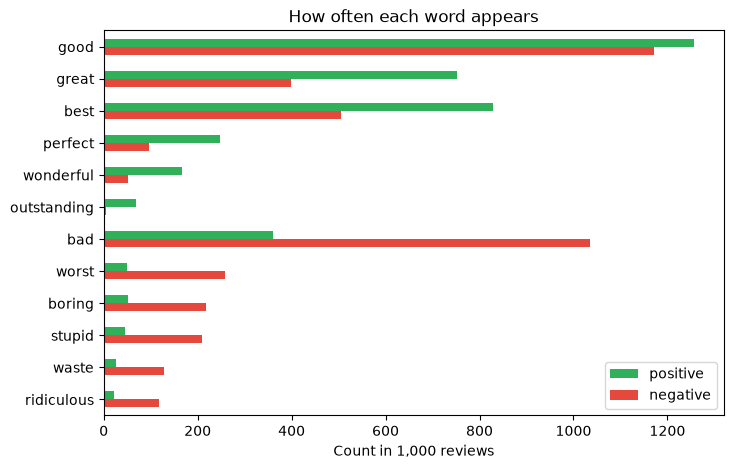

,good,great,best,perfect,wonderful,outstanding,bad,worst,boring,stupid,waste,ridiculous
positive,1257,753,829,248,166,69,361,49,52,45,26,22
negative,1172,398,505,96,51,5,1035,259,218,210,129,118


In [23]:
opinion_words = ["good", "great", "best", "perfect", "wonderful", "outstanding",
                 "bad", "worst", "boring", "stupid", "waste", "ridiculous"]

table = pd.DataFrame({
    "positive": [counts["pos"][w] for w in opinion_words],
    "negative": [counts["neg"][w] for w in opinion_words],
}, index=opinion_words)

table.plot.barh(figsize=(8, 5), color=["#30B05A", "#E5483D"])
plt.title("How often each word appears")
plt.xlabel("Count in 1,000 reviews")
plt.gca().invert_yaxis()
plt.show()

table.T

**What we see:**

- *good* is used almost equally in both groups: it is not a useful signal on its own.
- *great*, *perfect*, *wonderful* and especially *outstanding* lean clearly positive.
- *bad*, *worst*, *boring*, *stupid* and *waste* lean clearly negative.

So single words **do** carry sentiment, but some much more than others. A good method should give each word its own **weight**. TextBlob (section 6) uses weights written by people; logistic regression (section 10) learns them from the data.

### Which words are the most "one-sided"?

For every word, we want **one number** that says how much it leans positive or negative. We build it in three steps:

**1. The ratio:** how many times more often does the word appear in positive reviews than in negative ones?

$$\text{ratio} = \frac{\text{count in positive} + 1}{\text{count in negative} + 1}$$

The **+1** avoids dividing by 0 when a word never appears in one group (*shrek*: 0 negative reviews).

**2. The log2 of the ratio.** A plain ratio is lopsided: "twice as positive" is 2, but "twice as negative" is 0.5. The **log2** makes it symmetric around 0:

| ratio | log2 ratio | meaning |
|---|---|---|
| 4 | **+2** | 4× more often in positive reviews |
| 2 | **+1** | 2× more often in positive reviews |
| 1 | **0** | equally often |
| 0.5 | **−1** | 2× more often in negative reviews |
| 0.25 | **−2** | 4× more often in negative reviews |

Each step of 1 means "twice as one-sided". The sign tells the direction, the size tells the strength.

**Examples from our reviews:**

| word | positive | negative | ratio | log2 ratio |
|---|---|---|---|---|
| good | 1,257 | 1,172 | 1.07 | **+0.10** (no side) |
| great | 753 | 398 | 1.89 | **+0.92** (about 2× positive) |
| outstanding | 69 | 5 | 11.67 | **+3.54** (about 12× positive) |
| bad | 361 | 1,035 | 0.35 | **−1.52** (about 3× negative) |
| waste | 26 | 129 | 0.21 | **−2.27** (about 5× negative) |

**3. Only words that appear at least 40 times.** Rare words give extreme ratios by chance: a word seen twice, both times in a positive review, would look perfectly positive. With 40 or more appearances the ratio is more reliable.

<span style="color:red;"><b>Question:</b> Why do we take the log2 of the ratio, and not just the ratio?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **Symmetry:** with a plain ratio, "2× more positive" is 2 but "2× more negative" is 0.5. The log2 turns these into **+1** and **−1**: same strength, same size, opposite sign.
- **0 = no side:** positive numbers lean positive, negative numbers lean negative, like TextBlob's polarity.
- **Base 2 is easy to read:** each step of 1 means "twice as one-sided". +3 means 8× more often in positive reviews.

Sorting by the plain ratio would give the same order. The log makes the numbers easier to compare and to plot.

In [24]:
rows = []
for word in set(counts["pos"]) | set(counts["neg"]):
    p, n = counts["pos"][word], counts["neg"][word]
    if p + n >= 40:
        rows.append({"word": word, "pos": p, "neg": n, "log2 ratio": np.log2((p + 1) / (n + 1))})

ratios = pd.DataFrame(rows).sort_values("log2 ratio")
print("Most negative words:")
display(ratios.head(10).round(2))
print("Most positive words:")
display(ratios.tail(10).round(2))

Most negative words:


,word,pos,neg,log2 ratio
1216,nbsp,0,58,-5.88
1895,seagal,1,64,-5.02
1872,schumacher,2,47,-4.00
1448,anaconda,3,41,-3.39
2035,alicia,3,39,-3.32
905,ludicrous,3,38,-3.29
2248,flubber,4,41,-3.07
513,idiotic,4,40,-3.04
2047,godzilla,14,116,-2.96
1915,zeta,4,37,-2.93


Most positive words:


,word,pos,neg,log2 ratio
604,truman,121,11,3.35
376,outstanding,69,5,3.54
1462,damon,66,4,3.74
1444,cauldron,41,2,3.81
1175,bulworth,46,2,3.97
1165,lebowski,46,1,4.55
1086,flynt,62,1,4.98
2555,mulan,79,1,5.32
1158,gattaca,42,0,5.43
518,shrek,59,0,5.91


<span style="color:red;"><b>Question:</b> Many of the most one-sided words are names of films and actors (for example <i>seagal</i>, <i>shrek</i>, <i>mulan</i>). Is that a problem?</span>

<span style="color:green;"><b>Answer:</b></span><br>
It is a warning. These words are one-sided only because a few **specific films** were reviewed several times: the critics liked *Shrek* and *Mulan* and didn't like Steven Seagal films.

A model that learned *"seagal = negative"* would look clever on this dataset, but it would be wrong on a positive review of a new Seagal film, and useless on reviews of other films. This is called **overfitting to the data**: learning facts about *this* dataset instead of general rules about language. Keep it in mind for the next lessons.

## 6. Rule-based sentiment with TextBlob

Now we build our first sentiment analyser, **without any machine learning**. **Rule-based** means: people wrote down the knowledge (a list of word scores and a few rules), nothing is learned from data. TextBlob is a Python library that does this. It has a **lexicon**: a dictionary in which people gave thousands of words a score.

- **Polarity:** from −1 (very negative) to +1 (very positive)
- **Subjectivity:** from 0 (a fact) to 1 (an opinion)

For a sentence, TextBlob finds the words it knows and **averages** their scores.

In [25]:
for word in ["great", "good", "nice", "dull", "bad", "terrible", "horrendous", "boring"]:
    s = TextBlob(word).sentiment
    print(f"{word:12} polarity {s.polarity:+.2f}   subjectivity {s.subjectivity:.2f}")

great        polarity +0.80   subjectivity 0.75
good         polarity +0.70   subjectivity 0.60
nice         polarity +0.60   subjectivity 1.00
dull         polarity -0.29   subjectivity 0.50
bad          polarity -0.70   subjectivity 0.67
terrible     polarity -1.00   subjectivity 1.00
horrendous   polarity +0.00   subjectivity 0.00
boring       polarity -1.00   subjectivity 1.00


<span style="color:red;"><b>Question:</b> Why does <i>horrendous</i> get polarity 0 and subjectivity 0?</span>

<span style="color:green;"><b>Answer:</b></span><br>
*horrendous* is **not in TextBlob's lexicon**. The lexicon is a list of about 1,500 words (mostly adjectives) that people scored by hand. A word that is not on the list gets **0** and is ignored when TextBlob averages a sentence.

So a score of 0 can mean "neutral" **or** "unknown", and TextBlob can't tell the difference. Other strong words are missing too: *abysmal*, *unwatchable*, and even *disaster* and *masterpiece*, which appear more than 90 times each in our reviews. Rules only know the words someone wrote down.

In [26]:
for word in ["awful", "horrendous", "abysmal", "disaster", "masterpiece", "gem"]:
    print(f"{word:12} polarity {TextBlob(word).sentiment.polarity:+.2f}")

awful        polarity -1.00
horrendous   polarity +0.00
abysmal      polarity +0.00
disaster     polarity +0.00
masterpiece  polarity +0.00
gem          polarity +0.00


TextBlob also has a few rules: *very* makes a word stronger, and *not* flips it (and makes it weaker):

In [27]:
for s in ["The film was good.", "The film was very good.", "The film was not good.", "The film was not very good."]:
    print(f"{TextBlob(s).sentiment.polarity:+.2f}  {s}")

+0.70  The film was good.
+0.91  The film was very good.
-0.35  The film was not good.
-0.27  The film was not very good.


<span style="color:red;"><b>Question:</b> How does TextBlob get +0.91, −0.35 and −0.27 from the word <i>good</i> (+0.70)?</span>

<span style="color:green;"><b>Answer:</b></span><br>
TextBlob ignores the words it doesn't know (*the*, *film*, *was*) and combines *good* (+0.70) with the words right in front of it:

| sentence | calculation | score |
|---|---|---|
| good | 0.70 | **+0.70** |
| very good | 0.70 × 1.3 (*very* makes it stronger) | **+0.91** |
| not good | 0.70 × (−0.5) (*not* flips the sign and halves it) | **−0.35** |
| not very good | 0.70 ÷ 1.3 × (−0.5) | **−0.27** |

*Not very good* is milder than *not good*, just like when people say it. For a longer text, TextBlob does this for every scored word and then takes the **average**.

We can see the groups TextBlob found with `sentiment_assessments`:

In [28]:
for s in ["The film was very good.", "The film was not very good.", "The effects are nice, but dull."]:
    print(s, TextBlob(s).sentiment_assessments.assessments)

The film was very good. [(['very', 'good'], 0.9099999999999999, 0.7800000000000001, None)]
The film was not very good. [(['not', 'very', 'good'], -0.26923076923076916, 0.46153846153846156, None)]
The effects are nice, but dull. [(['nice'], 0.6, 1.0, None), (['dull'], -0.2916666666666667, 0.5, None)]


For a longer text it **averages** the scores of the words it knows. A real sentence from a negative review (`neg/cv086_19488.txt`):

In [29]:
print(f"{TextBlob('The effects are nice, but dull.').sentiment.polarity:+.2f}")

+0.15


*nice* (+0.60) and *dull* (−0.29) average to **+0.15**, so TextBlob says *positive*. The reviewer meant *negative*: the rules don't know that *but* makes the second half matter more.

### Our tricky sentences

We use these sentences in every NLP lesson. At the end of lesson 3 we compare all our methods on them. A person can label each one easily:

In [30]:
tricky = pd.DataFrame({
    "sentence": [
        "This movie was great!",
        "This movie was not good.",
        "Not bad at all, I really enjoyed it.",
        "I didn't hate it.",
        "I loved the trailer, but the film was a disaster.",
        "Oh great, another two hours of my life I will never get back.",
        "The acting was terrible but the story was wonderful.",
        "Absolutely brilliant, a must-see!",
    ],
    "truth": ["pos", "neg", "pos", "pos", "neg", "neg", "pos", "pos"],
})

tricky["polarity"] = tricky["sentence"].apply(lambda s: TextBlob(s).sentiment.polarity).round(2)
tricky["TextBlob says"] = np.where(tricky["polarity"] > 0, "pos", "neg")
tricky["correct?"] = np.where(tricky["TextBlob says"] == tricky["truth"], "yes", "NO")
tricky

,sentence,truth,polarity,TextBlob says,correct?
0,This movie was great!,pos,1.00,pos,yes
1,This movie was not good.,neg,-0.35,neg,yes
2,"Not bad at all, I really enjoyed it.",pos,0.42,pos,yes
3,I didn't hate it.,pos,-0.80,neg,NO
4,"I loved the trailer, but the film was a disaster.",neg,0.70,pos,NO
5,"Oh great, another two hours of my life I will never get back.",neg,0.40,pos,NO
6,The acting was terrible but the story was wonderful.,pos,0.00,neg,NO
7,"Absolutely brilliant, a must-see!",pos,1.00,pos,yes


<span style="color:red;"><b>Question:</b> Pick two sentences that TextBlob gets wrong. Why does it fail on them?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- *"I didn't hate it."*: the tokenizer splits *didn't* into *did* + *n't*, and the rule only flips the score after the word *not*. So TextBlob only sees *hate* (−0.8). Written as *"I did not hate it."* it scores +0.4.
- *"I loved the trailer, but the film was a disaster."*: *loved* is in the lexicon, *disaster* is not, so only the positive word counts. TextBlob also doesn't know that *but* makes the second half more important.
- *"Oh great, another two hours of my life I will never get back."*: sarcasm. The only word with a score is *great*, so the sentence looks positive.
- *"The acting was terrible but the story was wonderful."* is truly mixed: −1 and +1 average to exactly 0, which our rule calls negative.

Rules only know the words someone put in the lexicon, and only the patterns someone wrote a rule for.

### TextBlob on all 2,000 reviews

Now the real test. We need a **threshold**: the cut-off score. Polarity above it → positive, below → negative. We use **0**, the neutral middle of −1 … +1, chosen **before** looking at any results. This takes a few seconds.

In [31]:
df["polarity"] = df["text"].apply(lambda t: TextBlob(t).sentiment.polarity)
df["textblob_pred"] = np.where(df["polarity"] > 0, "pos", "neg")

accuracy = (df["textblob_pred"] == df["label"]).mean()
print(f"Accuracy: {accuracy:.1%}")

Accuracy: 60.0%


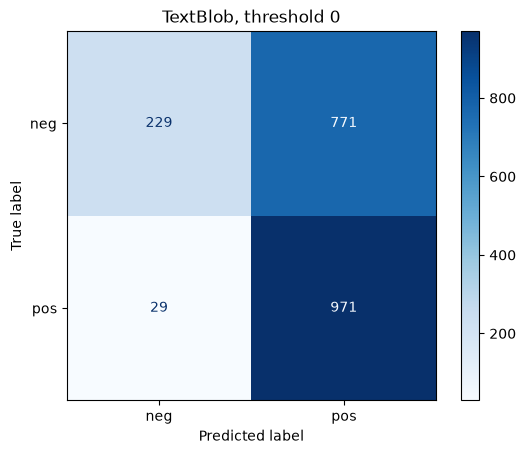

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(df["label"], df["textblob_pred"], cmap="Blues")
plt.title("TextBlob, threshold 0")
plt.show()

**Key observation:** TextBlob finds almost all positive reviews (971 of 1,000), but it also calls **771 of the 1,000 negative reviews positive**. Accuracy is only **60%** (1,200 of 2,000 right), not much better than the 50% of always saying "positive".

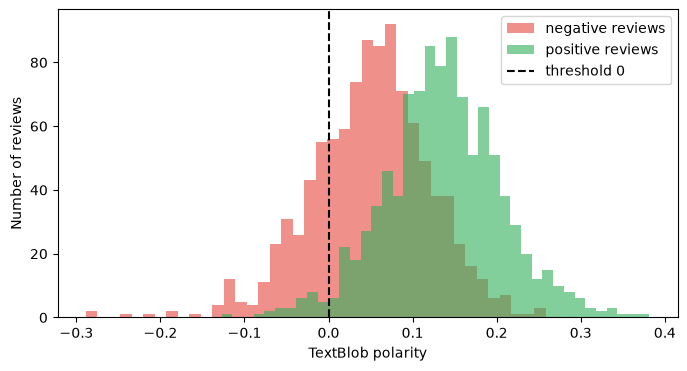

In [33]:
plt.figure(figsize=(8, 4))
plt.hist(df[df["label"] == "neg"]["polarity"], bins=40, alpha=0.6, color="#E5483D", label="negative reviews")
plt.hist(df[df["label"] == "pos"]["polarity"], bins=40, alpha=0.6, color="#30B05A", label="positive reviews")
plt.axvline(0, color="black", linestyle="--", label="threshold 0")
plt.xlabel("TextBlob polarity")
plt.ylabel("Number of reviews")
plt.legend()
plt.show()

<span style="color:red;"><b>Question:</b> Why do most negative reviews get a polarity above 0?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Look at the histogram: **both** groups sit mostly above 0. The negative reviews are only shifted a little to the left (average polarity 0.05 vs 0.14).

- **Averaging over 750 words:** a negative review still describes the plot, praises an actor or two (*"the only good thing..."*) and uses words like *good* and *best*. Averaged over a long text, the few strong negative words get diluted.
- **Missing words:** strong negative words are not always in the lexicon. Here is the shortest review in the dataset:

In [34]:
short = df.loc[df["fileid"] == "neg/cv506_17521.txt"]
print(short["text"].iloc[0])
print("Polarity:", round(short["polarity"].iloc[0], 2))
print("Score of 'horrendous':", TextBlob("horrendous").sentiment.polarity,
      "| score of 'extraordinarily':", round(TextBlob("extraordinarily").sentiment.polarity, 2))

this film is extraordinarily horrendous and i'm not going to waste any more words on it . 

Polarity: 0.21
Score of 'horrendous': 0.0 | score of 'extraordinarily': 0.33


*horrendous* has no score at all, but *extraordinarily* counts as positive, so this clearly negative review gets a **positive** polarity.

### Can we choose a better threshold?

In [35]:
for threshold in [0, 0.05, 0.1, 0.15]:
    pred = np.where(df["polarity"] > threshold, "pos", "neg")
    print(f"threshold {threshold:.2f}: accuracy {(pred == df['label']).mean():.1%}")

threshold 0.00: accuracy 60.0%
threshold 0.05: accuracy 68.4%
threshold 0.10: accuracy 74.6%
threshold 0.15: accuracy 67.0%


<span style="color:red;"><b>Question:</b> A threshold of 0.1 gives 75%. Can we report 75% as our result?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Not honestly. We **chose** 0.1 by looking at the labels of the same 2,000 reviews we then measured the accuracy on. That is like seeing the exam answers before the exam: the score looks better than it would be on **new** reviews.

The fair way: choose the threshold on one part of the data (the **training set**) and measure the accuracy on another part that we never looked at (the **test set**). We do exactly that in section 10. For now we keep the honest, untuned **60%**.

## 7. Bag of words: turning text into numbers

Machine learning models only understand **numbers**. The simplest way to turn a text into numbers is a **bag of words**:

1. Make a list of every word in all the texts: the **vocabulary**.
2. For each text, count how often each vocabulary word appears.

Every text becomes one row of numbers, with one column per word. Let's do it with three short sentences from our reviews:

In [36]:
from sklearn.feature_extraction.text import CountVectorizer

# from pos/cv521_15828, neg/cv875_5622 and neg/cv105_19135
mini = ["this is a really good movie.", "this is not a good movie.", "a bad movie is a bad movie."]

vectorizer = CountVectorizer()
X_mini = vectorizer.fit_transform(mini)

pd.DataFrame(X_mini.toarray(), columns=vectorizer.get_feature_names_out(), index=mini)

,bad,good,is,movie,not,really,this
this is a really good movie.,0,1,1,1,0,1,1
this is not a good movie.,0,1,1,1,1,0,1
a bad movie is a bad movie.,2,0,1,2,0,0,0


<span style="color:red;"><b>Question:</b> Here are two sentences. What do their bag-of-words rows look like?</span>

In [37]:
pair = ["boy likes girl", "girl likes boy"]   # both from pos/cv994_12270
v = CountVectorizer()
pd.DataFrame(v.fit_transform(pair).toarray(), columns=v.get_feature_names_out(), index=pair)

,boy,girl,likes
boy likes girl,1,1,1
girl likes boy,1,1,1


<span style="color:green;"><b>Answer:</b></span><br>
**Exactly the same.** A bag of words only counts words: it throws away the **order**, like shaking all the words of a sentence into a bag. *"boy likes girl"* and *"girl likes boy"* (both from the same review of a romantic comedy) tell different stories but get the same numbers.

For sentiment this is often acceptable, because opinion words like *great* or *boring* matter more than their position. Adding **bigrams** brings back a little of the order. In lesson 3 we meet models that read words **in context**.

Now the same for all 2,000 reviews:

In [38]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df["text"])

print("Shape (reviews, words):", X.shape)
print(f"Cells that are 0: {1 - X.nnz / (X.shape[0] * X.shape[1]):.1%}")
print("Different words per review, on average:", round((X > 0).sum(axis=1).mean()))

Shape (reviews, words): (2000, 39659)
Cells that are 0: 99.2%
Different words per review, on average: 333


<span style="color:red;"><b>Question:</b> Why are more than 99% of the cells 0?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Each review uses only a few hundred of the 39,659 words in the vocabulary. Here are three of our reviews and a few columns of `X`:

| review | the | film | not | outstanding | money | waste | seagal | shrek | … 39,651 more | different words used |
|---|---|---|---|---|---|---|---|---|---|---|
| Simon Birch (pos) | 30 | 7 | 4 | **2** | 0 | 0 | 0 | 0 | almost all 0 | 282 |
| "$4.25 back" (neg) | 45 | 3 | 3 | 0 | **1** | 0 | 0 | 0 | almost all 0 | 419 |
| "a bad movie is a bad movie" (neg) | 41 | 7 | 6 | 0 | 0 | 0 | 0 | 0 | almost all 0 | 401 |

Common words like *the* and *film* are filled in every row. Each specific word (*outstanding*, *money*, *seagal*…) is used by only a few reviews, so in most rows its cell is 0. On average a review uses about **333** different words. So in each row, about 39,300 of the 39,659 cells are 0: more than **99%**.

A table where almost everything is 0 is called **sparse**. scikit-learn stores it smartly: it only remembers the cells that are **not** 0. Otherwise 2,000 × 39,659 = about 79 million numbers would need a lot of memory for nothing.

This matrix `X`, together with the labels, is exactly what a machine learning model needs. But it has lost the word order. Next: bringing back a little order with n-grams, then a better way to fill the cells (TF-IDF).

In [39]:
cols = ["the", "film", "not", "outstanding", "money", "waste", "seagal", "shrek"]
ids = ["pos/cv181_14401.txt", "neg/cv499_11407.txt", "neg/cv105_19135.txt"]
rows = df.index[df["fileid"].isin(ids)]
col_idx = [vectorizer.vocabulary_[c] for c in cols]
table = pd.DataFrame(X[rows][:, col_idx].toarray(), columns=cols, index=df.loc[rows, "fileid"])
table["different words used"] = (X[rows] > 0).sum(axis=1).A1
table

,the,film,not,outstanding,money,waste,seagal,shrek,different words used
fileid,,,,,,,,,
neg/cv105_19135.txt,41,7,6,0,0,0,0,0,401
neg/cv499_11407.txt,45,3,3,0,1,0,0,0,419
pos/cv181_14401.txt,30,7,4,2,0,0,0,0,282


## 8. N-grams: keeping a little word order

The bag of words forgot the order: *not funny* became *not* + *funny*. An **n-gram** is a sequence of *n* words that sit next to each other: slide a window of *n* words along the sentence, one step at a time. Every neighbour pair is taken, in reading order: 5 words give 4 bigrams.

- **unigrams** (n = 1): *the*, *jokes*, *were*, ...
- **bigrams** (n = 2): *the jokes*, *jokes were*, *were not*, *not funny*
- **trigrams** (n = 3): *the jokes were*, *jokes were not*, *were not funny*

In [40]:
from nltk.util import ngrams

words = tokenize("The jokes were not funny")   # from neg/cv378_21982.txt
for n in [1, 2, 3]:
    print(f"n = {n}:", [" ".join(g) for g in ngrams(words, n)])

n = 1: ['the', 'jokes', 'were', 'not', 'funny']
n = 2: ['the jokes', 'jokes were', 'were not', 'not funny']
n = 3: ['the jokes were', 'jokes were not', 'were not funny']


Bigrams capture short phrases that single words miss. Let's count some in all reviews (here we keep the stopwords, because *the* and *of* are part of these phrases):

In [41]:
bigram_counts = {label: Counter() for label in ["pos", "neg"]}
for text, label in zip(df["text"], df["label"]):
    bigram_counts[label].update(ngrams(tokenize(text), 2))

phrases = [("waste", "of"), ("the", "worst"), ("not", "funny"), ("well", "worth"), ("must", "see")]

pd.DataFrame({
    "positive": [bigram_counts["pos"][p] for p in phrases],
    "negative": [bigram_counts["neg"][p] for p in phrases],
}, index=[" ".join(p) for p in phrases])

,positive,negative
waste of,7,67
the worst,39,178
not funny,1,27
well worth,18,1
must see,15,3


<span style="color:red;"><b>Question:</b> <i>waste</i> was already a negative word. What does the bigram <i>waste of</i> add?</span>

<span style="color:green;"><b>Answer:</b></span><br>
It makes the signal **cleaner**. *waste* alone can appear in a positive review (*"not a minute is wasted"*, *"a waste of a great actor, but the film works"*). *waste of* almost always means *"a waste of time / money / talent"*: it appears **67 times** in negative reviews and only **7 times** in positive ones.

Bigrams like *not funny* or *must see* also fix part of the negation problem from section 3: a negation usually sits right before its word, so one extra word catches it.

Neighbours also change the meaning of a balanced word like *good*:

In [42]:
phrases = [("very", "good"), ("pretty", "good"), ("only", "good"), ("not", "good"), ("pretty", "bad")]
pd.DataFrame({
    "positive": [bigram_counts["pos"][p] for p in phrases],
    "negative": [bigram_counts["neg"][p] for p in phrases],
}, index=[" ".join(p) for p in phrases])

,positive,negative
very good,100,54
pretty good,34,39
only good,1,13
not good,3,4
pretty bad,4,15


*very good* leans positive and *only good* is almost always negative (*"the only good thing about this film…"*). And *not good* is **rare**: critics write *"not very good"* or *"not a good film"*, so *not* is often not the direct neighbour of *good*. That is the limit of bigrams.

### Why stop at bigrams?

Longer windows catch more, but they cost a lot. Let's count the different n-grams in our reviews, how many appear only once, and how much memory a table of 2,000 reviews × all n-grams would need. (This takes a few seconds.)

In [43]:
rows = []
for n in [1, 2, 3]:
    v = CountVectorizer(ngram_range=(n, n))
    Xn = v.fit_transform(df["text"])
    totals = np.asarray(Xn.sum(axis=0)).ravel()
    rows.append({"n": n, "different n-grams": Xn.shape[1],
                 "seen only once": f"{(totals == 1).mean():.0%}",
                 "RAM full table (GB)": round(Xn.shape[0] * Xn.shape[1] * 8 / 1e9, 1),
                 "RAM zeros skipped (MB)": round((Xn.data.nbytes + Xn.indices.nbytes + Xn.indptr.nbytes) / 1e6)})
pd.DataFrame(rows)

,n,different n-grams,seen only once,RAM full table (GB),RAM zeros skipped (MB)
0,1,39659,35%,0.6,8
1,2,499250,76%,8.0,14
2,3,990798,90%,15.9,15


<span style="color:red;"><b>Question:</b> Why do people usually stop at bigrams?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **Too rare:** 90% of all trigrams appear only **once** in 2,000 reviews. A model can't learn a weight from a single example (Zipf's law again).
- **Too big:** a full table for trigrams would need about **16 GB** of memory, more than most laptops have. scikit-learn only stores the non-zero cells (a *sparse* matrix), which brings it down to about 15 MB, but every extra column still costs time and memory.

In section 10 we test what bigrams and trigrams do to the accuracy.

## 9. TF-IDF: not every word is equally interesting

**Why weight at all?** In a bag of words the biggest numbers go to the emptiest words: *the* appears about 38 times in an average review, *outstanding* once or twice (Zipf's law). **TF-IDF** (**T**erm **F**requency – **I**nverse **D**ocument **F**requency) fixes this. A *term* is a word, a *document* is one review.

**The formula**:

| piece | what it is | in words |
|---|---|---|
| **TF** (term frequency) | **the count** | how often the word appears in **this** review |
| **DF** (document frequency) | a count over all reviews | in how many reviews the word appears |
| **IDF** (inverse document frequency) | **the weight** | DF turned upside down: in every review → low weight, in few reviews → high weight |
| **TF-IDF** | **the weighted count** | TF × IDF, then scaled per review |

$$\text{IDF} = \ln\left(\frac{1 + n}{1 + \text{DF}}\right) + 1 \qquad n = \text{number of documents}$$

$$\text{TF-IDF} = \text{TF} \times \text{IDF} \quad \text{then every row is scaled to length 1}$$

A word scores high when it appears **often in this review** but **rarely in the others**.

### TF-IDF on three sentences

The same three sentences from our reviews as in the bag-of-words example.

**Step 1: TF = the count.** How often each word appears in each sentence. That is simply the **bag of words** from section 7.

In [44]:
from sklearn.feature_extraction.text import TfidfVectorizer

mini = ["this is a really good movie.", "this is not a good movie.", "a bad movie is a bad movie."]

counter = CountVectorizer()
tf = pd.DataFrame(counter.fit_transform(mini).toarray(), columns=counter.get_feature_names_out(), index=mini)
tf

,bad,good,is,movie,not,really,this
this is a really good movie.,0,1,1,1,0,1,1
this is not a good movie.,0,1,1,1,1,0,1
a bad movie is a bad movie.,2,0,1,2,0,0,0


**Step 2: IDF = the weight.** First DF: in how many sentences each word appears (each sentence counts once, however often the word is in it). Then IDF = ln((1 + n) / (1 + DF)) + 1, with n = 3 sentences.

In [45]:
n = len(mini)
df_count = (tf > 0).sum(axis=0)                      # DF: in how many sentences is the word?
idf_mini = np.log((1 + n) / (1 + df_count)) + 1     # IDF: the weight of each word
pd.DataFrame({"DF": df_count, "IDF (weight)": idf_mini.round(2)}).T

,bad,good,is,movie,not,really,this
DF,1.00,2.00,3.0,3.0,1.00,1.00,2.00
IDF (weight),1.69,1.29,1.0,1.0,1.69,1.69,1.29


*is* and *movie* are in all 3 sentences: IDF = ln(4/4) + 1 = **1.00**, the lowest weight. *bad*, *not* and *really* are in only 1 sentence: IDF = ln(4/2) + 1 = **1.69**. The weight is the same for a word in every sentence.

**Step 3: TF × IDF = the weighted count.** Multiply every count by its word's weight.

In [46]:
tfidf_mini = tf * idf_mini
tfidf_mini.round(2)

,bad,good,is,movie,not,really,this
this is a really good movie.,0.00,1.29,1.0,1.0,0.00,1.69,1.29
this is not a good movie.,0.00,1.29,1.0,1.0,1.69,0.00,1.29
a bad movie is a bad movie.,3.39,0.00,1.0,2.0,0.00,0.00,0.00


**Step 4: scale each row.** Long texts have bigger numbers just because they have more words. So scikit-learn divides every row by its length (the square root of the sum of its squared values), and every row ends up with the same "size" 1.

In [47]:
row_length = np.sqrt((tfidf_mini ** 2).sum(axis=1))
final = tfidf_mini.div(row_length, axis=0)
final.round(2)

,bad,good,is,movie,not,really,this
this is a really good movie.,0.00,0.45,0.35,0.35,0.00,0.59,0.45
this is not a good movie.,0.00,0.45,0.35,0.35,0.59,0.00,0.45
a bad movie is a bad movie.,0.83,0.00,0.25,0.49,0.00,0.00,0.00


In scikit-learn, `TfidfVectorizer` does all four steps in one line:

In [48]:
v = TfidfVectorizer()
sklearn_result = pd.DataFrame(v.fit_transform(mini).toarray(), columns=v.get_feature_names_out(), index=mini)
print("Same as our calculation:", np.allclose(final.values, sklearn_result.values))
sklearn_result.round(2)

Same as our calculation: True


,bad,good,is,movie,not,really,this
this is a really good movie.,0.00,0.45,0.35,0.35,0.00,0.59,0.45
this is not a good movie.,0.00,0.45,0.35,0.35,0.59,0.00,0.45
a bad movie is a bad movie.,0.83,0.00,0.25,0.49,0.00,0.00,0.00


**Row 3 by hand:** *"a bad movie is a bad movie."*

| word | TF (count) | DF | IDF (weight) | TF × IDF | ÷ row length 4.06 |
|---|---|---|---|---|---|
| bad | 2 | 1 | 1.69 | 3.39 | **0.83** |
| movie | 2 | 3 | 1.00 | 2.00 | **0.49** |
| is | 1 | 3 | 1.00 | 1.00 | **0.25** |

Row length = √(3.39² + 2.00² + 1.00²) = √16.5 ≈ 4.06.

**What we see:** *bad* and *movie* both appear twice (same count), but *bad* is rare (weight 1.69) and *movie* is everywhere (weight 1.00). That is why *bad* ends up with **0.83** and *movie* with only **0.49**. In row 2, *not* gets the highest value, because it is what makes that sentence different. TF-IDF turns down the volume of words that are everywhere, without a stopword list.

### TF-IDF on all 2,000 reviews

Now the weights (IDF) from all our reviews:

In [49]:
tfidf_all = TfidfVectorizer().fit(df["text"])
idf = pd.Series(tfidf_all.idf_, index=tfidf_all.get_feature_names_out())
in_reviews = pd.Series(np.asarray((X > 0).sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out())

words = ["the", "film", "not", "bad", "boring", "outstanding"]
pd.DataFrame({"DF: in how many reviews": in_reviews[words], "IDF (weight)": idf[words].round(2)})

,DF: in how many reviews,IDF (weight)
the,1999,1.00
film,1753,1.13
not,1680,1.17
bad,773,1.95
boring,217,3.22
outstanding,68,4.37


A worked example: one positive review (`pos/cv181_14401.txt`, about *Simon Birch*). TF is the count in this review, IDF the weight from all reviews:

In [50]:
one = df.loc[df["fileid"] == "pos/cv181_14401.txt", "text"].iloc[0]
counter_one = CountVectorizer().fit([one])
tf_one = pd.Series(counter_one.transform([one]).toarray()[0], index=counter_one.get_feature_names_out())
words = ["the", "film", "not", "outstanding"]
pd.DataFrame({"TF (count)": tf_one[words], "IDF (weight)": idf[words].round(2), "TF × IDF": (tf_one[words] * idf[words]).round(1)})

,TF (count),IDF (weight),TF × IDF
the,30,1.00,30.0
film,7,1.13,7.9
not,4,1.17,4.7
outstanding,2,4.37,8.7


Counted, *film* (7) beats *outstanding* (2). Weighted, *outstanding* (8.7) beats *film* (7.9). *the* stays big, but the gap shrinks, and the model will learn to ignore it.

**Careful with the word "weight":**

- **IDF** is the **weight** of a word: one number per word, the same in every review (*bad* = 1.95 in all our reviews).
- **TF-IDF** is the **weighted count**: count × IDF, then scaled. One number per word **per review**.
- In section 10, logistic regression learns **its own weights**, one per word (*bad* = −2.51). Those say which direction a word pushes.<br> 

**The model uses both: TF-IDF value × learned weight, added up over all words.**

<span style="color:red;"><b>Question:</b> Why is TF-IDF better than removing stopwords for sentiment?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Removing stopwords is all or nothing: a word is either in the list (gone) or not (kept with full weight). We saw that the list contains *not*, which we need.

TF-IDF is gradual: common words get a **smaller** weight, rare and specific words a **bigger** one, and nothing is thrown away. *not* stays in the data, just with a moderate weight because it is fairly common.

## 10. Our first algorithm: logistic regression

TextBlob used scores **written by people**. Now the computer **learns** the scores from labelled reviews.

### Step 1: training set and test set

In section 6 we saw the danger of choosing something by looking at the answers. From now on we always split the data:

- **Training set (80%, 1,600 reviews):** the model learns from these.
- **Test set (20%, 400 reviews):** hidden until the end, only used to measure.

In [51]:
from sklearn.model_selection import train_test_split

df["y"] = (df["label"] == "pos").astype(int)            # models need numbers: 1 = positive, 0 = negative
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
y_train, y_test = train_df["y"].values, test_df["y"].values
print("Training reviews:", len(train_df), "| Test reviews:", len(test_df))

Training reviews: 1600 | Test reviews: 400


`test_size=0.2` puts 20% of the reviews (400) into the test set, `stratify=df["y"]` keeps 50% positive reviews in both parts and `random_state=42` makes the split the same every time. **Lessons 2 and 3 use exactly the same split**, so all scores are comparable.

For a fair comparison, here is TextBlob on the same 400 test reviews:

In [52]:
textblob_test_acc = ((test_df["polarity"] > 0).astype(int) == y_test).mean()
print(f"TextBlob on the test set: {textblob_test_acc:.1%}")

TextBlob on the test set: 59.5%


### Step 2: turn the reviews into TF-IDF numbers

One important rule: the vectorizer learns its vocabulary (**fit**) from the **training set only**. The test reviews are only **transformed** with that vocabulary, exactly like new reviews in real life.

In [53]:
tfidf = TfidfVectorizer()
X_train = tfidf.fit_transform(train_df["text"])     # learn the vocabulary + compute TF-IDF
X_test = tfidf.transform(test_df["text"])           # same vocabulary, no learning
print("Training matrix:", X_train.shape, "| Test matrix:", X_test.shape)

Training matrix: (1600, 36352) | Test matrix: (400, 36352)


<span style="color:red;"><b>Question:</b> Why don't we call <code>fit_transform</code> on the test set too?</span>

<span style="color:green;"><b>Answer:</b></span><br>
`fit` **learns** something from the data, here the vocabulary and the IDF weights. If we fitted on the test set, information from the test reviews would leak into the model. This is called **data leakage**, and it makes the test score too optimistic. With `transform` only, a word the model has never seen is simply ignored, just like in a real new review. That is also why both matrices have the **same number of columns**.

### Step 3: train logistic regression

Logistic regression learns **one weight for every word**:

- a **positive** weight pushes a review towards *positive*,
- a **negative** weight pushes it towards *negative*,
- a weight near **0** means the word doesn't matter.

For a review it adds up *weight × TF-IDF value* for all its words, plus a bias, and turns the total into a probability between 0 and 1. Nobody writes the weights: they are **learned** from the 1,600 training reviews.

In [54]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)                         # learning happens here

lr_acc = logreg.score(X_test, y_test)
print(f"Logistic regression accuracy on the test set: {lr_acc:.1%}")

Logistic regression accuracy on the test set: 80.2%


From about 60% to about 80%, with three lines of code. Now the best part: we can read what it learned.

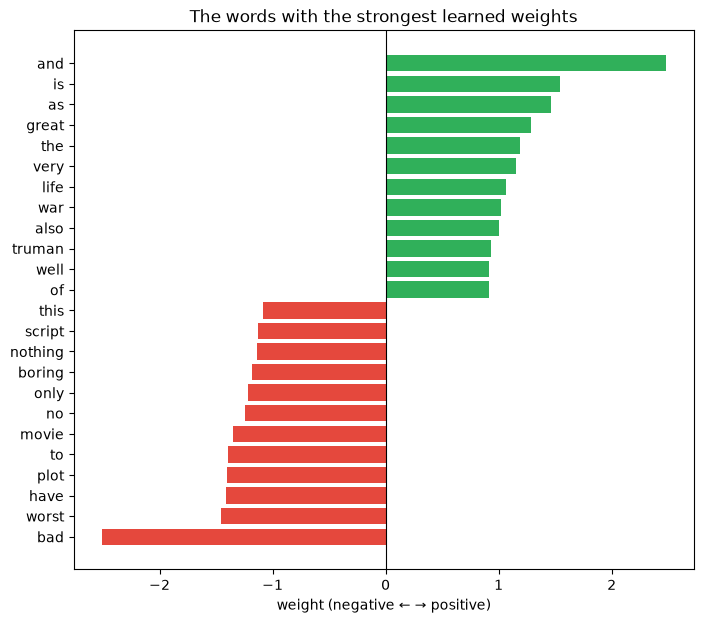

In [55]:
weights = pd.Series(logreg.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
top = pd.concat([weights.head(12), weights.tail(12)])

plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values, color=["#E5483D" if w < 0 else "#30B05A" for w in top.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("The words with the strongest learned weights")
plt.xlabel("weight (negative ← → positive)")
plt.show()

<span style="color:red;"><b>Question:</b> Look at the words with the strongest weights. Are they all opinion words? Is that what you expected?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Only some of them. The model found clear opinion words without anyone telling it: *bad*, *worst*, *boring*, *nothing* on the negative side; *great* and *well* on the positive side.

But many are surprising:

- *the*, *and*, *is*, *of*, *as* get **positive** weights. Positive reviews are longer on average (787 vs 706 words, section 1), so they simply contain more of these little words.
- *plot*, *script*, *movie* and *this* get **negative** weights: negative reviews complain about *the plot* and *the script*, and say *"this movie"* where positive ones say *"the film"*.
- *truman* is positive because *The Truman Show* got good reviews: the film-name trap from section 5.

The model learns **whatever helps on the training data**, which is not always what a person would choose. Always look at the weights before you trust a model's explanation.

### Step 4: what do bigrams and trigrams add?

Back to the question from section 8. We train the same model with words only, words + bigrams, and words + bigrams + trigrams (this takes about a minute):

In [56]:
for ngram_range in [(1, 1), (1, 2), (1, 3)]:
    vec = TfidfVectorizer(ngram_range=ngram_range)
    Xtr = vec.fit_transform(train_df["text"])
    model = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    acc = model.score(vec.transform(test_df["text"]), y_test)
    print(f"ngram_range {ngram_range}: {Xtr.shape[1]:>9,} columns, test accuracy {acc:.1%}")

ngram_range (1, 1):    36,352 columns, test accuracy 80.2%
ngram_range (1, 2):   456,487 columns, test accuracy 80.8%
ngram_range (1, 3): 1,264,304 columns, test accuracy 70.5%


Bigrams help a little (about 2 more test reviews right). Trigrams add a million rare columns and make the model **worse**: more features is not always better. Bigrams are the sweet spot; our model keeps it simple with single words.

### Step 5: our tricky sentences

In [57]:
tricky["ML model"] = np.where(logreg.predict(tfidf.transform(tricky["sentence"])) == 1, "pos", "neg")
tricky["ML prob. positive"] = logreg.predict_proba(tfidf.transform(tricky["sentence"]))[:, 1].round(2)   # above 0.5 → positive

print("TextBlob correct:", (tricky["TextBlob says"] == tricky["truth"]).sum(), "of 8")
print("ML model correct:", (tricky["ML model"] == tricky["truth"]).sum(), "of 8")
tricky[["sentence", "truth", "TextBlob says", "ML model", "ML prob. positive"]]

TextBlob correct: 4 of 8
ML model correct: 2 of 8


,sentence,truth,TextBlob says,ML model,ML prob. positive
0,This movie was great!,pos,pos,neg,0.34
1,This movie was not good.,neg,neg,neg,0.19
2,"Not bad at all, I really enjoyed it.",pos,pos,neg,0.22
3,I didn't hate it.,pos,neg,neg,0.34
4,"I loved the trailer, but the film was a disaster.",neg,pos,neg,0.46
5,"Oh great, another two hours of my life I will never get back.",neg,pos,pos,0.55
6,The acting was terrible but the story was wonderful.,pos,neg,neg,0.38
7,"Absolutely brilliant, a must-see!",pos,pos,neg,0.47


<span style="color:red;"><b>Question:</b> The ML model is much better on the 400 test reviews. Why is it not better on the tricky sentences?</span>

<span style="color:green;"><b>Answer:</b></span><br>
The tricky sentences are short and **very different** from the training data:

- *ML prob. positive* is the model's probability of *positive*; above **0.5** it says positive (a threshold again, like with TextBlob). All probabilities stay between 0.2 and 0.55: the model is **unsure**. It learned from long reviews (~750 words); in an 8-word sentence only a few words count.
- It **leans negative**: even *"Absolutely brilliant, a must-see!"* gets 0.47. *this* (−1.08) and *movie* (−1.35) pull every "This movie…" sentence down, and short sentences have few of the little words like *the* and *and* that carry positive weights.
- *hate* and *disaster* are too rare in the training reviews to get a real weight (both about 0).
- It is still a bag of words: no **order**, no **sarcasm**. scikit-learn cuts *didn't* to *didn* (the *t* is dropped), and it can't flip *hate*.

So a better score on the test set doesn't mean the model **understands** language. Lesson 2 builds neural networks with **word vectors**; lesson 3 brings models that read words **in context**.

### Our scoreboard

From now on every score is measured on **the same 400 test reviews**, plus the 8 tricky sentences.

In [58]:
scoreboard = pd.DataFrame({
    "method": ["1. Rules: TextBlob", "2. TF-IDF + logistic regression", "3. Neural network", "4. Pretrained transformer"],
    "lesson": [1, 1, 2, 3],
    "test accuracy": [f"{textblob_test_acc:.1%}", f"{lr_acc:.1%}", "?", "?"],
    "tricky sentences": [f"{(tricky['TextBlob says'] == tricky['truth']).sum()} of 8", f"{(tricky['ML model'] == tricky['truth']).sum()} of 8", "?", "?"],
})
scoreboard

,method,lesson,test accuracy,tricky sentences
0,1. Rules: TextBlob,1,59.5%,4 of 8
1,2. TF-IDF + logistic regression,1,80.2%,2 of 8
2,3. Neural network,2,?,?
3,4. Pretrained transformer,3,?,?


<span style="color:red;"><b>Question:</b> Logistic regression wins on the 400 real reviews but loses on the tricky sentences. Which model would you put into a product?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Usually the 80% model: the 400 test reviews are the real use case, the 8 tricky sentences are hand-picked examples. But the tricky sentences show **what kind of mistakes** a model makes, and a user who writes *"I didn't hate it"* and gets *negative* will stop trusting the product. Good teams look at both: the big number **and** the examples.

## 11. *(Optional)* Marvin, the friendly chatbot

Marvin reads what you type, checks the **sentiment** and picks an answer to match. If he finds a **noun phrase**, he asks you more about it. All the tools come from this lesson: TextBlob polarity (section 6) and noun phrases (section 4).

In [59]:
import random

def marvin_reply(user_input):
    blob = TextBlob(user_input)
    polarity = blob.sentiment.polarity

    if polarity > 0.3:
        mood = random.choice(["That sounds great!", "Wonderful, I'm happy for you."])
    elif polarity < -0.3:
        mood = random.choice(["Oh no, that sounds hard.", "I'm sorry to hear that."])
    else:
        mood = random.choice(["I see.", "Interesting.", "Hmm, tell me more."])

    if blob.noun_phrases:
        topic = blob.noun_phrases[0]
        return f"{mood} Can you tell me more about {topic}?"
    return mood

random.seed(1)
for message in ["I watched an amazing science fiction film yesterday",
                "My old laptop is terrible and slow",
                "I am going to the supermarket"]:
    print("You:  ", message)
    print("Marvin:", marvin_reply(message))
    print()

You:   I watched an amazing science fiction film yesterday
Marvin: That sounds great! Can you tell me more about amazing science fiction film?

You:   My old laptop is terrible and slow
Marvin: Oh no, that sounds hard. Can you tell me more about old laptop?

You:   I am going to the supermarket
Marvin: Interesting.



To chat with Marvin yourself, remove the `#` in front of the lines below and run the cell. Type **bye** to stop.

In [61]:
# print("Hello, I am Marvin, the friendly robot. Type 'bye' to stop.")
# while True:
#     user_input = input("> ")
#     if user_input.lower() == "bye":
#         print("It was nice talking to you, goodbye!")
#         break
#     print(marvin_reply(user_input))

## 12. *(Optional)* A simple text generator with n-grams

N-grams can also **write** text. We count, in a large collection of sentences (the Brown corpus), which word follows each pair of words. Then we start from two words and keep picking a likely next word.

This is the same idea as a large language model like ChatGPT, only much simpler: it predicts the next word from the last **two** words instead of from the whole text.

In [60]:
from nltk.corpus import brown

def train_ngram_model(n=3, num_sentences=20000):
    """For every context of n-1 words, count which words come next."""
    model = {}
    for sentence in brown.sents()[:num_sentences]:
        tokens = ["<START>"] * (n - 1) + [w.lower() for w in sentence] + ["<END>"]
        for i in range(len(tokens) - n + 1):
            context = tuple(tokens[i:i + n - 1])        # the n-1 words before
            next_word = tokens[i + n - 1]               # the word that follows
            model.setdefault(context, Counter())[next_word] += 1
    return model

model = train_ngram_model(n=3)
print("Contexts learned:", len(model))
print("After 'of the', the most common next words are:", model[("of", "the")].most_common(5))

Contexts learned: 206439
After 'of the', the most common next words are: [('new', 61), ('most', 43), ('united', 39), ('``', 37), ('church', 34)]


In [62]:
def generate(seed, model, n=3, length=15, temperature=1.0):
    """Start from the seed text and add up to `length` words."""
    words = seed.lower().split()
    for _ in range(length):
        context = tuple((["<START>"] * (n - 1) + words)[-(n - 1):])
        if context not in model:
            break
        candidates = model[context]
        if temperature == 0:
            next_word = candidates.most_common(1)[0][0]          # always the most likely word
        else:
            weights = [count ** (1 / temperature) for count in candidates.values()]
            next_word = random.choices(list(candidates), weights=weights)[0]
        if next_word == "<END>":
            break
        words.append(next_word)
    return " ".join(words)

random.seed(0)
print("temperature 0:  ", generate("the president", model, temperature=0))
for _ in range(3):
    print("temperature 1:  ", generate("the president", model, temperature=1))

temperature 0:   the president said he had been a member of the new york , in the world .
temperature 1:   the president clearly was going to can soup , served daily since the first word from his
temperature 1:   the president is otis m. waters , is just one example .
temperature 1:   the president of the theatre to the male chorus of the old bridge has survived through the


<span style="color:red;"><b>Question:</b> What does the temperature change?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **Temperature 0:** always pick the most common next word. The text is predictable and often repeats itself.
- **Temperature 1:** pick words in proportion to how often they followed. Each run gives a different, more varied text.
- **Higher temperature** (try 2 or 3): rare words get more chances, and the text becomes more surprising and less sensible.

Chatbots like ChatGPT have the same setting: low temperature for factual answers, higher for creative writing.

## 13. Recap

**What we did:**

| Section | What we learned |
|---|---|
| 1. Load | 2,000 movie reviews, balanced: 1,000 positive and 1,000 negative, about 750 words each. Always saying "positive" gives 50%. Zipf: a few words are everywhere, most are rare. |
| 2. Tokenization | `split()`, `word_tokenize` and a regex give different tokens. Choose the one that fits the task. Subword tokens (BPE) handle new words. |
| 3. Cleaning | Lowercase, remove stopwords and lemmatize so the same word looks the same. **Careful:** *not* is a stopword. |
| 4. POS and noun phrases | Tags find the adjectives (opinions) and the noun phrases (topics). |
| 5. Which words take sides? | The most common words are the same in both groups. Opinion words like *outstanding* or *waste* are one-sided. Film names can be one-sided too, a trap. |
| 6. Rule-based sentiment | TextBlob averages word scores. It gets **60%** of the reviews right (59.5% on the test set), and fails on negation, sarcasm and missing words. |
| 7. Bag of words | Every review becomes a row of word counts: 2,000 × 39,659, more than 99% zeros. Word order is lost. |
| 8. N-grams | Bigrams keep short phrases like *waste of* and *not funny*. Trigrams are too rare and too big. |
| 9. TF-IDF | Words that are everywhere get a low weight, rare and specific words a high one. Nothing is thrown away. |
| 10. Logistic regression | Train on 1,600 reviews, test on 400. It learns one weight per word and beats TextBlob by about 20 points, but still fails most tricky sentences. |

**Key takeaways:**

- **Text has to become numbers** before a computer can learn from it.
- **Cleaning choices depend on the task**: removing *not* is fine for topics but bad for sentiment.
- **Rules are easy to understand but brittle**: they only know the words and patterns someone wrote down.
- **Don't tune on your test data**: split into training and test set, and `fit` only on the training set.
- **Learning beats hand-written rules** when we have labelled data, and simple models can show **why** they decide.

**Next lesson: neural networks and embeddings.** We discover that logistic regression is **one neuron**, connect many neurons into a network, and train our own network with **word vectors** (embeddings) on the same reviews.